# wave prediction with mslp and wind

this notebook-style script:
- runs data preprocessing for mslp and 10 m wind (u, v)
- prepares tensors for deep learning
- trains a transformer-based model
- reloads the trained model and makes predictions

## imports and paths

In [2]:
%load_ext autoreload
%autoreload 2
#this is to avoid to restart the kernel everytime we change our helper functions e.g. utils ...

In [3]:
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader

# import project modules
from preprocess_wave_mslp_wind import process_wind_data, process_mslp_data, process_wave_data
from train_wave_transformer import train_and_save_model
from predict_wave_transformer import load_model_checkpoint, predict_wave
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_squared_error, r2_score

## helper functions

In [4]:
def build_3d_tensor_from_df(df: pd.DataFrame, window: int) -> torch.Tensor:
    """
    from hourly data in df (time × features), build a torch.float32 tensor
    of shape (n_samples, window, n_features) using sliding windows.

    for each i >= window, we take rows [i-window, ..., i-1] as one sample.
    """
    arr_list = []
    values = df.values.astype(np.float32)
    for i in range(window, len(df) + 1):
        arr_list.append(values[i - window:i, :])
    X = np.stack(arr_list, axis=0)  # (n, window, n_features)
    return torch.from_numpy(X)

In [5]:
#we need this to reverse the flatterned lon/lat data
def infer_lat_lon_from_columns(columns):
    lats = []
    lons = []
    for c in columns:
        lat, lon = c.split("_")
        lats.append(float(lat))
        lons.append(float(lon))

    lats = np.array(lats)
    lons = np.array(lons)

    unique_lats = np.unique(lats)
    unique_lons = np.unique(lons)

    return unique_lats, unique_lons

In [6]:
#3d tensors -> 4d tensors: to help with the CNN signal extractions...
def build_4d_tensor_from_df(
    df: pd.DataFrame,
    window: int
) -> torch.Tensor:
    """
    Builds tensor:
      (n_samples, window, lat, lon)

    Assumes columns are ordered:
      lon varies fastest, lat varies slowest (row-major grid).
    """

    # infer grid
    lats, lons = infer_lat_lon_from_columns(df.columns)
    n_lat, n_lon = len(lats), len(lons)

    T = len(df)
    values = df.values.astype(np.float32)

    # sanity check
    assert values.shape[1] == n_lat * n_lon, \
        "Column count does not match inferred lat/lon grid"

    # reshape: time × lat × lon
    values_3d = values.reshape(T, n_lat, n_lon)

    # sliding windows
    samples = []
    for t in range(window - 1, T):
        samples.append(values_3d[t - window + 1 : t + 1])

    return torch.from_numpy(np.stack(samples))

In [7]:
def drop_non_continuous_windows(df: pd.DataFrame, window: int = 6) -> pd.DataFrame:
    """
    drops rows which cannot form a continuous hourly window of given size.
    keeps only timestamps where the last `window` steps are strictly 1-hour apart.
    """
    # difference between timestamps
    dt = df.index.to_series().diff()

    # a valid hourly step
    one_hour = pd.Timedelta(hours=1)

    # boolean mask: True where the step *is not* 1 hour
    gap_mask = dt != one_hour
    gap_mask.iloc[0] = False  # first row cannot be judged, keep it as non-gap

    # rows affected: any row that depends on previous 'window' timestamps
    invalid_indices = set()

    gap_positions = np.where(gap_mask.values)[0]

    for pos in gap_positions:
        # drop this row AND the following window-1 rows
        start = pos
        end = min(pos + window, len(df))
        invalid_indices.update(range(start, end))

    # keep only valid rows
    valid_rows = [i for i in range(len(df)) if i not in invalid_indices]
    df_clean = df.iloc[valid_rows].copy()

    return df_clean

In [8]:
def theta_conversion(thq_sin, thq_cos):
    angle_rad = np.arctan2(thq_sin, thq_cos)
    angle_rad = np.mod(angle_rad, 2 * np.pi)  # wrap to [0, 2pi)
    angle_deg = np.rad2deg(angle_rad)
    return angle_deg

In [9]:
def compute_metrics(y_obs, y_pred):
    """Compute RMSE, bias, MAE, R², Spearman r, N."""
    mask = np.isfinite(y_obs) & np.isfinite(y_pred)
    y_true, y_hat = y_obs[mask], y_pred[mask]

    rmse = root_mean_squared_error(y_true, y_hat)
    bias = np.mean(y_hat - y_true)
    mae = mean_absolute_error(y_true, y_hat)
    r2 = r2_score(y_true, y_hat)
    rs = spearmanr(y_true, y_hat)[0]
    n = len(y_true)

    return rmse, bias, mae, r2, rs, n

In [10]:
#check the skill scores
def compute_skill_metrics_for_dfs(obs_df, pred_df):
    """Return metrics for each column in obs_df and pred_df."""
    cols = obs_df.columns.intersection(pred_df.columns)
    out = {}

    for col in cols:
        y_obs = obs_df[col].values
        y_pred = pred_df[col].values
        rmse, bias, mae, r2, rs, n = compute_metrics(y_obs, y_pred)
        out[col] = {
            "RMSE": rmse,
            "Bias": bias,
            "MAE": mae,
            "R2": r2,
            "Spearman": rs,
            "NObs": int(n),
        }

    return pd.DataFrame(out).T

## data directories

In [11]:
# base data directory used in preprocessing script
data_dir = Path("../data")

# wave data (adjust if you use a different file or location) ELB, NST
wave_path = data_dir / "coastdat_wave_SEE.csv"

# paths to preprocessed parquet files
windU_path = data_dir / "stdanom_windU_data.parquet"
windV_path = data_dir / "stdanom_windV_data.parquet"
mslp_path  = data_dir / "stdanom_mslp_data.parquet"

# directory where models will be saved
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

## step 1 -- data preprocessing

this will:
- read raw netcdf files for mslp and wind, and wave
- standardise anomalies
- save parquet files used in later steps

if you have already run this once, you can skip this cell.

In [12]:
#if you have already preprocessed the atmospheric data, use False
run_preprocessing = False

In [13]:
%%time
if run_preprocessing:
    print("running wind preprocessing...")
    process_wind_data()
    print("running mslp preprocessing...")
    process_mslp_data()
else:
    print("skipping preprocessing, using existing parquet files.")

skipping preprocessing, using existing parquet files.
CPU times: user 139 μs, sys: 37 μs, total: 176 μs
Wall time: 161 μs


In [14]:
wave_file_pattern = "WAM_0044_MNB_NCEP_CD3_1948_2023.*.nc"
wave_variables=["hs", "tm2", "thq"]

In [15]:
%%time
run_preprocessing = False
if run_preprocessing:
    print("running wave preprocessing...")
    process_wave_data()
else:
    print("skipping preprocessing, using existing csv/parquet files.")

skipping preprocessing, using existing csv/parquet files.
CPU times: user 131 μs, sys: 35 μs, total: 166 μs
Wall time: 149 μs


## step 2 -- load preprocessed data and build model inputs

In [16]:
# load standardised mslp and wind data
print("loading standardised mslp and wind data...")

stdanom_windU = pd.read_parquet(windU_path)
stdanom_windV = pd.read_parquet(windV_path)
stdanom_mslp  = pd.read_parquet(mslp_path)

# ensure time index is datetime and sorted
for df in (stdanom_windU, stdanom_windV, stdanom_mslp):
    if not isinstance(df.index, pd.DatetimeIndex):
        df.index = pd.to_datetime(df.index)
    df.sort_index(inplace=True)
print("done!")

loading standardised mslp and wind data...
done!


In [17]:
for name, df in {"MSLP": stdanom_mslp, "WindU": stdanom_windU, "WindV": stdanom_windV}.items():
    print(f"{name}: {len(df.columns)}")

MSLP: 2400
WindU: 400
WindV: 400


In [18]:
# load wave data
print("loading wave data...")
wave_data = pd.read_csv(wave_path, index_col=0)
wave_data.index = pd.to_datetime(wave_data.index)
wave_data.sort_index(inplace=True)
print("done!")

loading wave data...
done!


In [19]:
# rename tm2 to t0--better to move to preprocesse.py 
if "tm2" in wave_data.columns:
    wave_data.rename(columns={"tm2": "t0"}, inplace=True)

# if 'delta' is present, rename it as thq (direction)
if "delta" in wave_data.columns and "thq" not in wave_data.columns:
    wave_data = wave_data.rename(columns={"delta": "thq"})

In [20]:
# restrict to overlapping time range across all datasets
common_index = wave_data.index
common_index = common_index.intersection(stdanom_mslp.index)
common_index = common_index.intersection(stdanom_windU.index)
common_index = common_index.intersection(stdanom_windV.index)

wave_data = wave_data.loc[common_index]
stdanom_mslp = stdanom_mslp.loc[common_index]
stdanom_windU = stdanom_windU.loc[common_index]
stdanom_windV = stdanom_windV.loc[common_index]
print(f"aligned length: {len(common_index)}\nfrom {common_index[0]} to {common_index[-1]}")

aligned length: 666215
from 1948-01-01 01:00:00 to 2023-12-31 23:00:00


In [21]:
# remove rows where any wave variable is missing, and drop corresponding times
mask_nan = wave_data.isnull().any(axis=1)
missing_dates = wave_data.index[mask_nan]

if len(missing_dates) > 0:
    print(f"found {len(missing_dates)} rows with missing wave data; removing them.")
else:
    print("no missing wave data found.")

wave_data = wave_data.loc[~wave_data.index.isin(missing_dates)]
stdanom_mslp = stdanom_mslp.loc[~stdanom_mslp.index.isin(missing_dates)]
stdanom_windU = stdanom_windU.loc[~stdanom_windU.index.isin(missing_dates)]
stdanom_windV = stdanom_windV.loc[~stdanom_windV.index.isin(missing_dates)]

found 21 rows with missing wave data; removing them.


In [22]:
# convert wave direction to radians and add sin/cos components.  assumes column 'thq' is in degrees. adjust if needed
if wave_data["thq"].max() > 2 * np.pi + 1e-3:
    # assume degrees, convert to radians
    wave_data["thq"] = np.deg2rad(wave_data["thq"].values)

wave_data["thq_sin"] = np.sin(wave_data["thq"])
wave_data["thq_cos"] = np.cos(wave_data["thq"])

In [23]:
np.sin(400)

np.float64(-0.8509193596391765)

<span style="color:#E60046; font-size:20px; font-weight:bold;">
!!   ensures 6-hour sequences have no gaps...
</span>

In [24]:
# remove all timestamps where the preceding window is not fully continuous
window = 6

wave_data      = drop_non_continuous_windows(wave_data,      window)
stdanom_mslp   = drop_non_continuous_windows(stdanom_mslp,   window)
stdanom_windU  = drop_non_continuous_windows(stdanom_windU,  window)
stdanom_windV  = drop_non_continuous_windows(stdanom_windV,  window)

In [25]:
# build predictor 3D arrays
X_mslp = build_4d_tensor_from_df(stdanom_mslp, window=window)  #or build_3d_tensor_from_df
X_windU = build_4d_tensor_from_df(stdanom_windU, window=window)
X_windV = build_4d_tensor_from_df(stdanom_windV, window=window)

# build target array y: [hs, t0, thq_sin, thq_cos]
target_cols = ["hs", "t0", "thq_sin", "thq_cos"]
y_array = wave_data[target_cols].values.astype(np.float32)
y_full = torch.from_numpy(y_array)
# to align shapes, we drop the first (window-1) entries from y
y = y_full[window - 1:]
y_date_stamps = wave_data.index[window - 1:]

print("shapes after windowing:")
print("X_mslp :", X_mslp.shape)
print("X_windU:", X_windU.shape)
print("X_windV:", X_windV.shape)
print("y      :", y.shape)

shapes after windowing:
X_mslp : torch.Size([666141, 6, 40, 60])
X_windU: torch.Size([666141, 6, 20, 20])
X_windV: torch.Size([666141, 6, 20, 20])
y      : torch.Size([666141, 4])


In [26]:
%%time
save_tensors = False
if save_tensors:
    print("saving the tensors...")
    # now save the tensors. so that we can call the .py script as a slurm job. if we want to run on GPU...  
    # directory to store prepared tensors for gpu training
    tensor_dir = Path("../data/prepared_tensors")
    tensor_dir.mkdir(parents=True, exist_ok=True)
    
    # save tensors and metadata in a single checkpoint file
    tensor_ckpt_path = tensor_dir / "wave_mslp_wind_tensors_4d.pt" #check whether you are using 3d or 4d data
    
    # convert datetime index to iso strings to keep it serialisable
    y_dates_str = y_date_stamps.astype("datetime64[ns]").astype(str).tolist()
    
    torch.save(
        {
            "X_mslp": X_mslp,           # (n, 6, 1600) or (n, 6, 40, 60) <-- if you go with 4d with CNN layer
            "X_windU": X_windU,         # (n, 6, 400) or (n, 6, 40, 40) <-- if you go with 4d with CNN layer
            "X_windV": X_windV,         # (n, 6, 400) or (n, 6, 40, 40) <-- if you go with 4d with CNN layer
            "y": y,                     # (n, 4)
            "y_dates": y_dates_str,     # list of iso-formatted timestamps
            "window": window,
            "target_cols": target_cols,
        },
        tensor_ckpt_path,
    )
    pd.Series(y_date_stamps).to_csv(tensor_dir / "y_dates.csv", index=False)
    print(f"saved tensors to: {tensor_ckpt_path}")
else:
    print("skipping tensor saving, using existing files.")
    # use saved tensors and metadata from the checkpoint file
    tensor_dir = Path("../data/prepared_tensors")
    tensor_ckpt_path = tensor_dir / "wave_mslp_wind_tensors_4d.pt" #check whether you are using 3d or 4d data

skipping tensor saving, using existing files.
CPU times: user 36 μs, sys: 36 μs, total: 72 μs
Wall time: 109 μs


## step 3 -- train the transformer model and save checkpoint

`train_and_save_model` will:
- split data into train / validation / test internally (sequentially)
- standardise the target y using train statistics
- train with early stopping
- save a checkpoint with:
- model weights
- hyper-parameters
- normalisation stats for y -->

In [27]:
ckpt = torch.load(tensor_ckpt_path, map_location="cpu")

X_mslp  = ckpt["X_mslp"]
X_windU = ckpt["X_windU"]
X_windV = ckpt["X_windV"]
y       = ckpt["y"]
y_dates = ckpt["y_dates"]  # list of strings

/tmp/ipykernel_1547253/2678915041.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(tensor_ckpt_path, map_location="cpu")


In [28]:
# if any array has a different number of rows. the program raises an AssertionError and stops execution!!
assert X_mslp.shape[0] == X_windU.shape[0] == X_windV.shape[0] == y.shape[0], \
    "different number of rows detected!"

**change hyper-parameters here:**
- ../config/transformer_hyperparams.txt

**alternatively you can run the slurm_train_job.py file as a slurm job with GPU support**

In [29]:
%%time
#if you have already trained a model, use False
train_a_new_model = False
if train_a_new_model:
    print("training a new DL model... using hyperparameters from /config/transformer_hyperparams")
    train_and_save_model(
        X_mslp=X_mslp,
        X_windU=X_windU,
        X_windV=X_windV,
        y=y,
        y_dates=y_dates,
        models_dir="../models",
    )
else:
    print("going to use a trained model in /models...")

going to use a trained model in /models...
CPU times: user 71 μs, sys: 108 μs, total: 179 μs
Wall time: 168 μs


## step 4 -- reload best model and make predictions

here we:
- load the most recent checkpoint (by date)
- run the model on a sample of the data
- obtain predictions in physical units [hs, t0, thq_sin, thq_cos]

In [30]:
# compute test split
N = X_mslp.shape[0]
ratio = 0.7894620698765736   # ratio chosen so that the split occurs exactly at 2007/2008
n_train = int(0.8166789314257354 * ratio * N) # ratio chosen so that the split occurs exactly at 1996/1997
n_val   = int(ratio * N)

# load latest checkpoint
ckpts = sorted(models_dir.glob("*_mslp_wind_transformer_4d.pt"))
ckpt_path = ckpts[-1]  #for the latest... change loc if needed.
print(f"{ckpt_path.name} is selected")
model, y_mean, y_std, h = load_model_checkpoint(str(ckpt_path))

X_mslp_test  = X_mslp[n_val:]
X_windU_test = X_windU[n_val:]
X_windV_test = X_windV[n_val:]
y_test       = y[n_val:]
test_dates   = pd.to_datetime(y_dates[n_val:])

2026_05_06_mslp_wind_transformer_4d.pt is selected


/work/gg0303/g260244/metascales/wave-forecasts/codes/predict_wave_transformer.py:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(ckpt_path, map_loc

In [31]:
print(f'total amount of training samples: {len(y)-len(y_test)}\ntotal amount of testing samples: {len(y_test)}')

total amount of training samples: 525893
total amount of testing samples: 140248


In [32]:
#double check with the training cell hwere we have the same dates
print(f"test period begins at: {test_dates[0]} \ntest period ends   at: {test_dates[-1]}")

test period begins at: 2008-01-01 01:00:00 
test period ends   at: 2023-12-31 23:00:00


**note:** 

CNN inference can use more memory than training if you skip batching. because spatial encoders multiply the effective batch size by time.

In [35]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

batch_size = 512   # batched inferfence to avoid memory overuse

dl_test = DataLoader(
    TensorDataset(X_mslp_test, X_windU_test, X_windV_test),
    batch_size=batch_size,
    shuffle=False,
)

In [36]:
model.eval()
preds = []

with torch.no_grad():
    for xb_mslp, xb_u, xb_v in dl_test:
        xb_mslp = xb_mslp.to(device)
        xb_u    = xb_u.to(device)
        xb_v    = xb_v.to(device)

        # forward pass
        preds_norm = model(xb_mslp, xb_u, xb_v)

        # un-normalise
        preds_ph = preds_norm * y_std + y_mean
        preds.append(preds_ph.cpu())

# concatenate all batches
preds_ph = torch.cat(preds, dim=0)

In [37]:
# build dataframe
pred_np = preds_ph.cpu().numpy()
df_pred = pd.DataFrame(
    {
        "hs": pred_np[:, 0],
        "t0": pred_np[:, 1],
        "thq_sind": pred_np[:, 2],
        "thq_cos": pred_np[:, 3],
    },
    index=test_dates,
)

In [38]:
#use the y_test and build another df for the hindcast 
df_hcst = pd.DataFrame(y_test,index=test_dates,columns=["hs", "t0", "thq_sind", "thq_cos"])

## step 5 -- convert predicted direction back to angle

the model outputs:
- hs
- t0
- thq_sin
- thq_cos

In [39]:
# here we convert the last two back to a direction angle in radians or degrees.
df_pred = df_pred.assign(
    thq = theta_conversion(df_pred["thq_sind"].values, df_pred["thq_cos"].values)
).drop(columns=["thq_sind", "thq_cos"])

df_hcst = df_hcst.assign(
    thq = theta_conversion(df_hcst["thq_sind"].values, df_hcst["thq_cos"].values)
).drop(columns=["thq_sind", "thq_cos"])

## step 6 -- save predictions and hindcast data in the test period.

at this point you can:
- compare `pred_df` with the corresponding subset of `wave_data`
- compute skill scores
- plot time series or scatter plots for your manuscript
- so that you can run the figures.ipynb and visualise the results to see the perforamnce

In [40]:
compute_skill_metrics_for_dfs(df_hcst, df_pred)

,RMSE,Bias,MAE,R2,Spearman,NObs
hs,0.210291,-0.050334,0.152512,0.935859,0.939488,140248.0
t0,0.638462,-0.043047,0.430730,0.746934,0.831644,140248.0
thq,31.924107,-2.145251,13.238455,0.761511,0.921384,140248.0


   *skill metrics of the model trained on 24.03.2026 as a comparison  -->*
<div align="left">

| Variable | RMSE | Bias | MAE | R² | Spearman | NObs |
|:---------|:-----|:------|:------|:------|:----------|:---------|
| hs       | 0.208028 | -0.006990 | 0.147265 | 0.937232 | 0.953484 | 140,248 |
| t0       | 0.587284 | 0.051014  | 0.398005 | 0.785879 | 0.870677 | 140,248 |
| thq_deg  | 29.547848 | 1.479497 | 11.835914 | 0.795693 | 0.933123 | 140,248 |

</div>

##### Bias and MAE error calculations for angles in degrees

In [34]:
df_pred['thq'].max()

np.float32(359.99274)

In [35]:
df_pred['thq'], df_hcst['thq']

(2008-01-01 01:00:00    172.619583
 2008-01-01 02:00:00    175.076752
 2008-01-01 03:00:00    177.191864
 2008-01-01 04:00:00    176.922211
 2008-01-01 05:00:00    174.605270
                           ...    
 2023-12-31 19:00:00     23.783211
 2023-12-31 20:00:00     24.594294
 2023-12-31 21:00:00     27.033688
 2023-12-31 22:00:00     36.755718
 2023-12-31 23:00:00     42.753738
 Name: thq, Length: 140248, dtype: float32,
 2008-01-01 01:00:00    161.311691
 2008-01-01 02:00:00    161.318787
 2008-01-01 03:00:00    161.167847
 2008-01-01 04:00:00    160.847885
 2008-01-01 05:00:00    160.518127
                           ...    
 2023-12-31 19:00:00     23.762955
 2023-12-31 20:00:00     21.619234
 2023-12-31 21:00:00     26.958761
 2023-12-31 22:00:00     36.148533
 2023-12-31 23:00:00     40.748158
 Name: thq, Length: 140248, dtype: float32)

In [36]:
def angular_difference_deg(pred, obs):
    diff = pred - obs
    # wrap to [-180, 180)
    diff = (diff + 180) % 360 - 180
    return diff

In [37]:
angular_difference_deg(df_pred['thq'], df_hcst['thq']).mean()

np.float32(1.1920059)

In [38]:
np.abs(angular_difference_deg(df_pred['thq'], df_hcst['thq'])).mean()

np.float32(10.448626)

# extra work for the manuscript discussions---to be deleted...

### storm events

In [39]:
wave_data.loc[:, ['hs']].quantile(.75),wave_data.loc[:, ['hs']].quantile(.95)

(hs    1.48489
 Name: 0.75, dtype: float64,
 hs    2.745926
 Name: 0.95, dtype: float64)

In [40]:
import storm_detection
wam_wave_storms = storm_detection.detect_wave_storms(
    df_hcst.loc[:, ['hs','t0','thq']], 
    freq_hours = 1.0,
    threshold1= 1.48,
    threshold2 = 2.74,
    min_duration= 6,
    min_gap = 48
)

In [41]:
wam_wave_storms['storm_power'] = wam_wave_storms['duration_hours'] * wam_wave_storms['max_hs']**2

In [42]:
idx = (
    wam_wave_storms
    .groupby(wam_wave_storms['start_time'].dt.year)['storm_power']
    .idxmax()
)

In [43]:
wam_wave_storms.loc[idx].sort_values('start_time').loc[:,:]

,start_time,end_time,duration_hours,max_hs,mean_hs,mean_t0,mean_thq,storm_id,storm_power
5,2008-02-21 13:00:00,2008-03-07 00:00:00,347.0,7.380053,2.797606,6.004509,132.404205,6,18899.415943
26,2009-09-30 20:00:00,2009-10-05 11:00:00,111.0,5.766103,2.978107,6.181708,136.043411,27,3690.521347
41,2010-10-18 16:00:00,2010-10-26 05:00:00,181.0,5.044798,2.624688,5.728148,132.214462,42,4606.447376
60,2011-12-02 08:00:00,2011-12-21 15:00:00,463.0,7.302068,2.447299,5.727572,133.148849,61,24687.249935
62,2012-01-02 15:00:00,2012-01-09 02:00:00,155.0,6.354467,3.729437,6.800479,130.278824,63,6258.784866
90,2013-11-28 08:00:00,2013-12-10 00:00:00,280.0,8.268929,3.072735,6.209279,131.931931,91,19145.049133
102,2014-12-09 19:00:00,2014-12-25 22:00:00,387.0,6.471594,2.788785,5.803279,126.833946,103,16208.153881
104,2015-01-08 19:00:00,2015-01-18 12:00:00,233.0,6.322485,3.010238,5.895739,112.889908,105,9313.900887
132,2016-12-22 22:00:00,2016-12-28 08:00:00,130.0,7.662793,3.242290,6.390260,125.638496,133,7633.390884
134,2017-01-11 00:00:00,2017-01-15 16:00:00,112.0,7.954803,4.066069,7.587887,139.970886,135,7087.236389


In [44]:
stdanom_mslp.max().max(),stdanom_mslp.min().min()

(np.float32(3.8352942), np.float32(-6.818439))

In [45]:
stdanom_windU.max().max(),stdanom_windU.min().min()

(np.float32(5.57366), np.float32(-4.216931))

In [46]:
stdanom_windV.max().max(),stdanom_windV.min().min()

(np.float32(5.1619377), np.float32(-6.0330744))

In [47]:
stdanom_mslp.loc['2013-12-06 02:00:00':'2013-12-06 07:00:00'].max().max(),stdanom_mslp.loc['2013-12-06 02:00:00':'2013-12-06 07:00:00'].min().min()

(np.float32(1.936142), np.float32(-4.7066865))

In [48]:
stdanom_windU.loc['2013-12-06 02:00:00':'2013-12-06 07:00:00'].max().max(),stdanom_windU.loc['2013-12-06 02:00:00':'2013-12-06 07:00:00'].min().min()

(np.float32(3.8535068), np.float32(1.1146823))

In [49]:
stdanom_windV.loc['2013-12-06 02:00:00':'2013-12-06 07:00:00'].max().max(),stdanom_windV.loc['2013-12-06 02:00:00':'2013-12-06 07:00:00'].min().min()

(np.float32(-0.6459445), np.float32(-4.2573357))

### *****

In [50]:
stdanom_mslp.loc['2016-12-26 22:00:00':'2016-12-27 03:00:00'].max().max(), stdanom_mslp.loc['2019-01-08 04:00:00':'2019-01-08 09:00:00'].min().min()

(np.float32(2.7113159), np.float32(-2.5446866))

In [51]:
stdanom_windU.loc['2016-12-26 22:00:00':'2016-12-27 03:00:00'].max().max(), stdanom_windU.loc['2019-01-08 04:00:00':'2019-01-08 09:00:00'].min().min()

(np.float32(2.9222522), np.float32(-0.034077834))

In [52]:
stdanom_windV.loc['2016-12-26 22:00:00':'2016-12-27 03:00:00'].max().max(), stdanom_windV.loc['2019-01-08 04:00:00':'2019-01-08 09:00:00'].min().min()

(np.float32(0.04214607), np.float32(-3.9398062))

In [53]:
stdanom_mslp.loc['2019-01-08 04:00:00':'2019-01-08 09:00:00'].max().max(), stdanom_mslp.loc['2019-01-08 04:00:00':'2019-01-08 09:00:00'].min().min()

(np.float32(2.0589864), np.float32(-2.5446866))

In [54]:
stdanom_windU.loc['2019-01-08 04:00:00':'2019-01-08 09:00:00'].max().max(), stdanom_windU.loc['2019-01-08 04:00:00':'2019-01-08 09:00:00'].min().min()

(np.float32(3.3124516), np.float32(-0.034077834))

In [55]:
stdanom_windV.loc['2019-01-08 04:00:00':'2019-01-08 09:00:00'].max().max(), stdanom_windV.loc['2019-01-08 04:00:00':'2019-01-08 09:00:00'].min().min()

(np.float32(0.23029888), np.float32(-3.9398062))

In [56]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [57]:
df_hcst.loc['2017-12-24 01:00:00':].head(50)

,hs,t0,thq
2017-12-24 01:00:00,3.047779,5.746166,116.503647
2017-12-24 02:00:00,3.153190,5.930993,118.483261
2017-12-24 03:00:00,3.147111,6.138734,119.957321
2017-12-24 04:00:00,3.048467,6.191419,120.485298
2017-12-24 05:00:00,2.942774,6.162571,120.367188
2017-12-24 06:00:00,2.845969,6.052889,119.806511
2017-12-24 07:00:00,2.745431,5.894618,118.820999
2017-12-24 08:00:00,2.751557,5.628479,116.550819
2017-12-24 09:00:00,2.815918,5.490146,114.026634
2017-12-24 10:00:00,2.851003,5.498375,112.546989


In [58]:
wave_data.loc['2018-01-08 21:00:00':].head(50)

,hs,t0,thq,thq_sin,thq_cos
time,,,,,
2018-01-08 21:00:00,2.166058,4.140791,4.438806,-0.962809,-0.270183
2018-01-08 22:00:00,2.134587,4.130687,4.451731,-0.966221,-0.257716
2018-01-08 23:00:00,2.088316,4.102275,4.466458,-0.969911,-0.243460
2018-01-09 00:00:00,2.002366,4.088280,4.468038,-0.970294,-0.241927
2018-01-09 01:00:00,1.880119,4.062783,4.460379,-0.968413,-0.249351
2018-01-09 02:00:00,1.754871,4.027369,4.442592,-0.963825,-0.266536
2018-01-09 03:00:00,1.670005,3.914049,4.438259,-0.962661,-0.270709
2018-01-09 04:00:00,1.591409,3.825808,4.450985,-0.966028,-0.258437
2018-01-09 05:00:00,1.532873,3.698490,4.481494,-0.973462,-0.228849


/work/gg0303/g260244/metascales/wave-forecasts/codes/storm_detection.py:215: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(labels)
/work/gg0303/g260244/metascales/wave-forecasts/codes/storm_detection.py:215: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(labels)
/work/gg0303/g260244/metascales/wave-forecasts/codes/storm_detection.py:215: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(labels)
/work/gg0303/g260244/metascales/wave-forecasts/codes/storm_detection.py:215: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(labels)
/work/gg0303/g260244/metascales/wave-forecasts/codes/storm_d

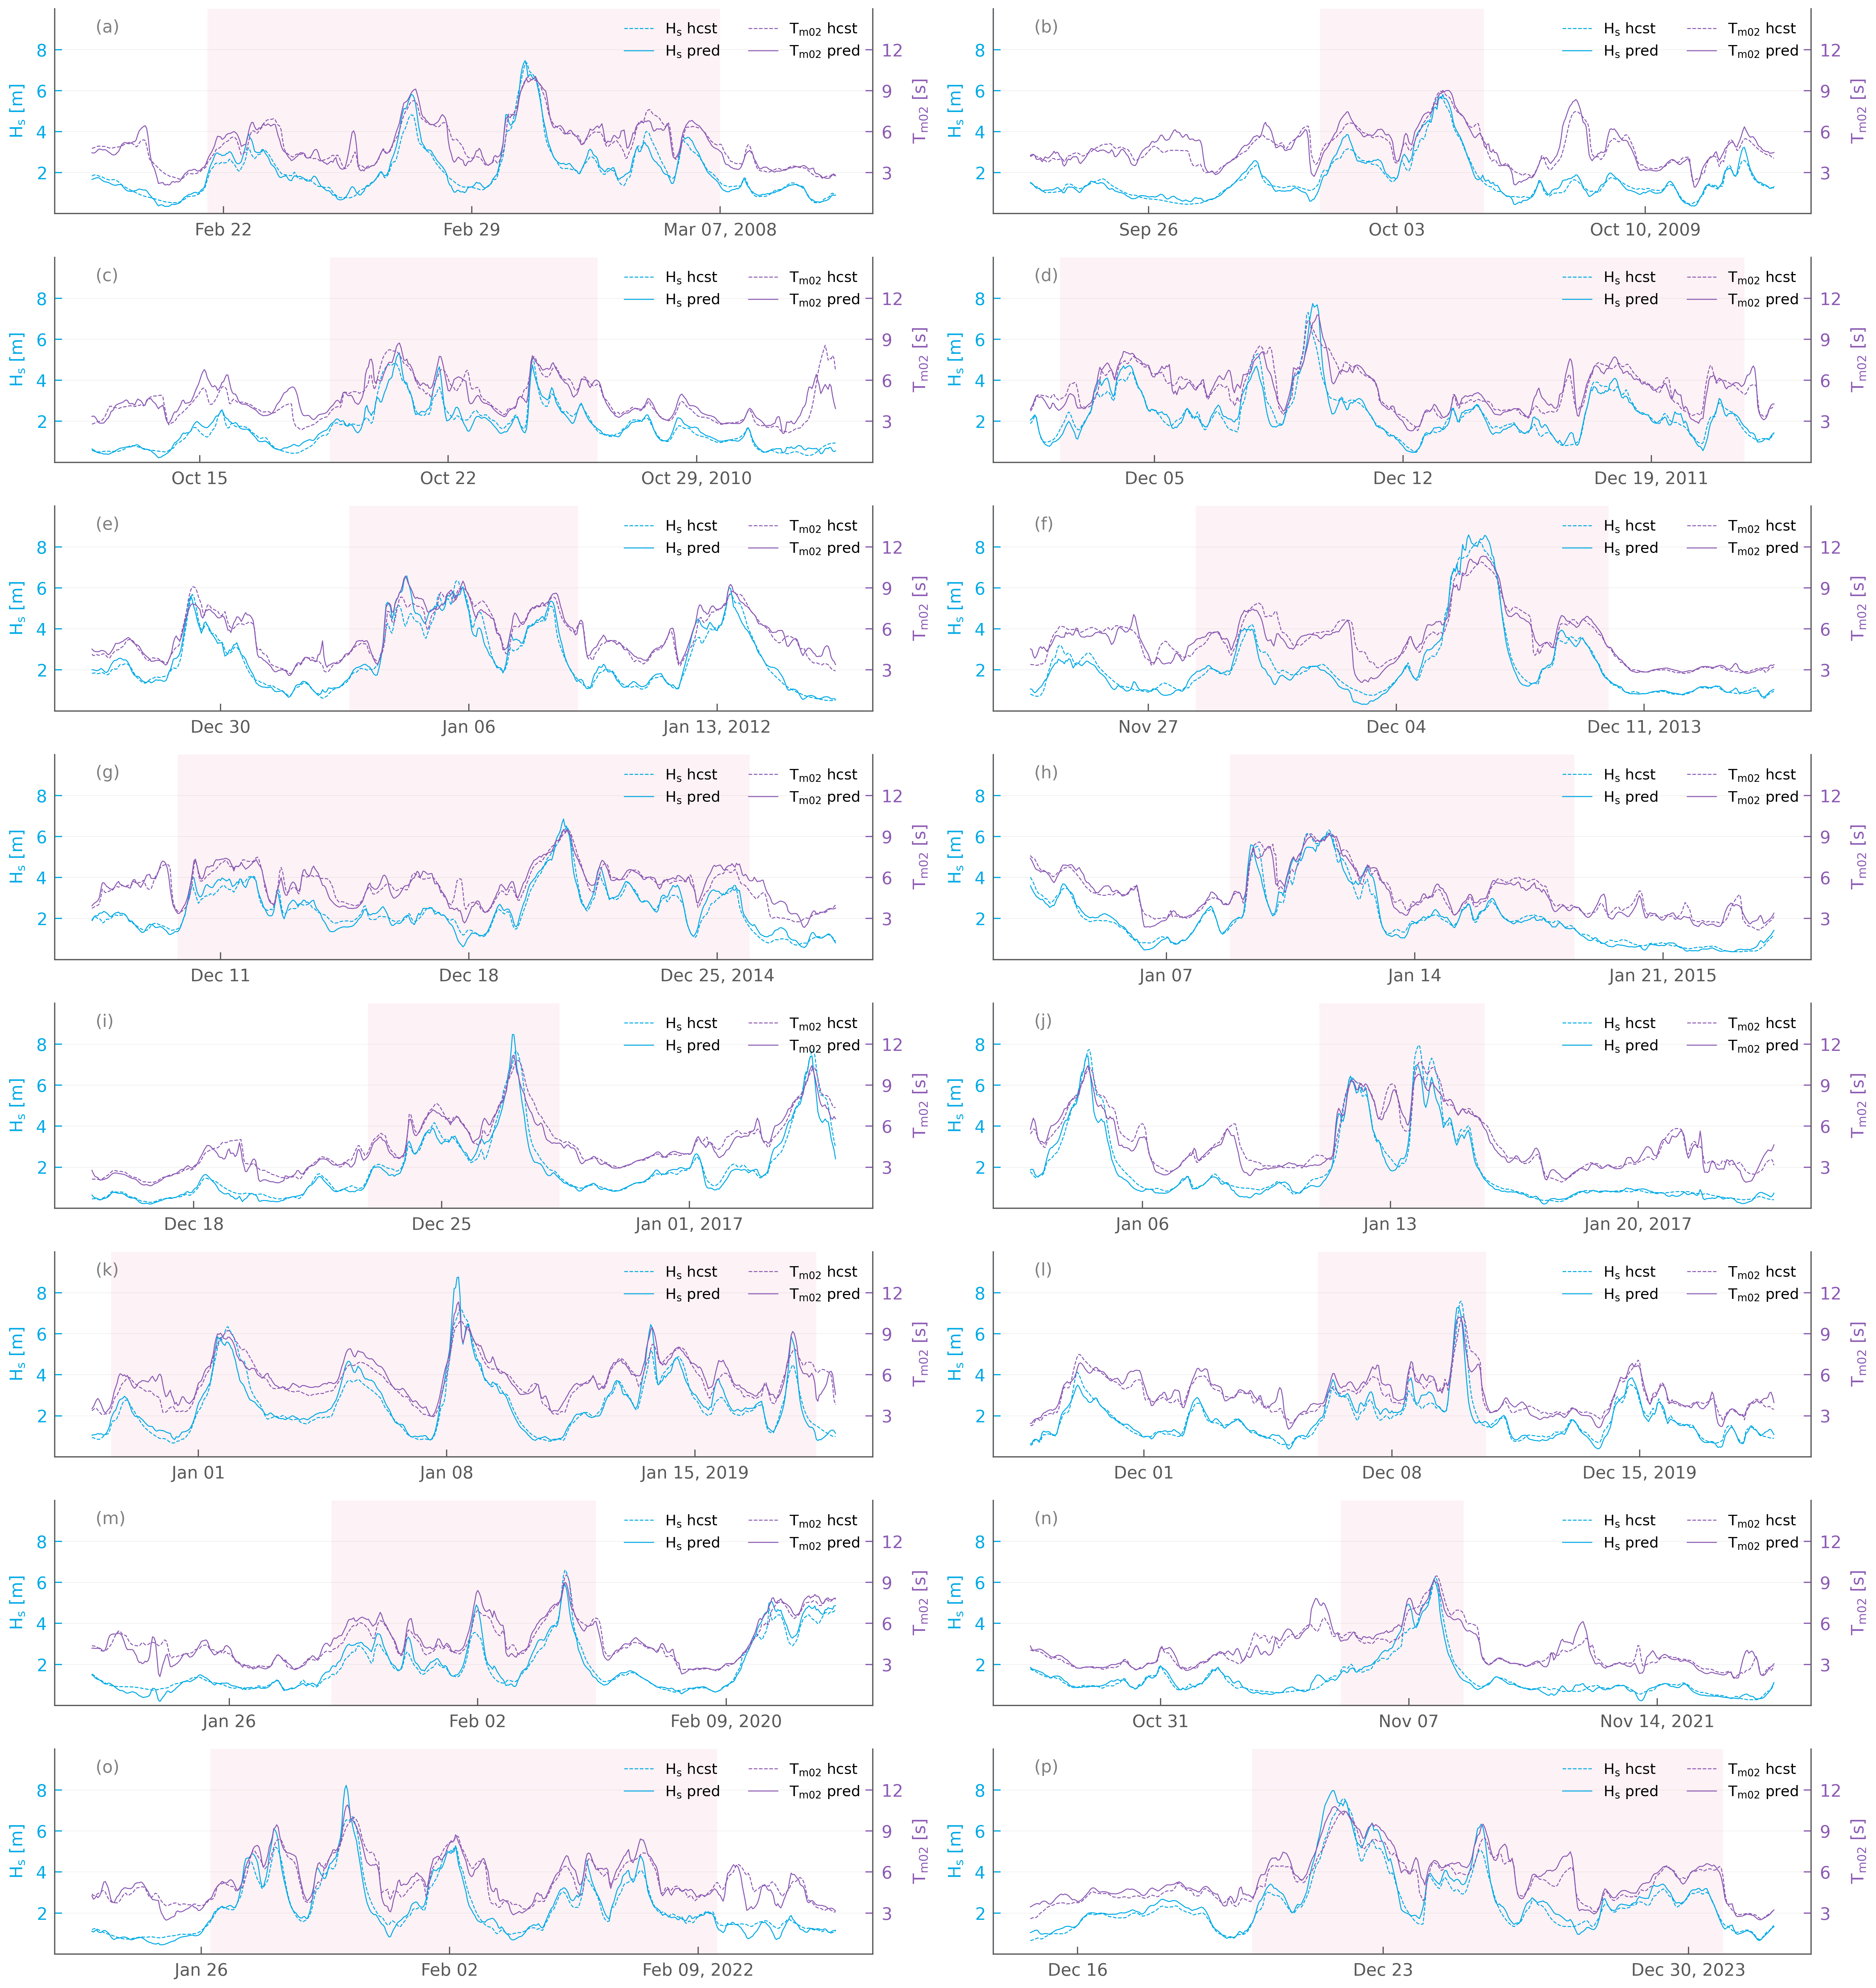

In [59]:
fig, axes = plt.subplots(8, 2, figsize=(10.8, 11.439), dpi=600)     #7.2 6.5  --10.8, 12 works ...
storm_detection.plot_storm(df_hcst,df_pred, '2008-02-21 13:00:00','2008-03-07 00:00:00', ax=axes[0,0], fig_num="(a)")
storm_detection.plot_storm(df_hcst,df_pred, '2009-09-30 20:00:00','2009-10-05 11:00:00	', ax=axes[0,1], fig_num="(b)")
storm_detection.plot_storm(df_hcst,df_pred, '2010-10-18 16:00:00','2010-10-26 05:00:00	', ax=axes[1,0], fig_num="(c)")
storm_detection.plot_storm(df_hcst,df_pred, '2011-12-02 08:00:00','2011-12-21 15:00:00', ax=axes[1,1], fig_num="(d)")
storm_detection.plot_storm(df_hcst,df_pred, '2012-01-02 15:00:00','2012-01-09 02:00:00', ax=axes[2,0], fig_num="(e)")
storm_detection.plot_storm(df_hcst,df_pred, '2013-11-28 08:00:00','2013-12-10 00:00:00', ax=axes[2,1], fig_num="(f)")
storm_detection.plot_storm(df_hcst,df_pred, '2014-12-09 19:00:00','2014-12-25 22:00:00', ax=axes[3,0], fig_num="(g)")
storm_detection.plot_storm(df_hcst,df_pred, '2015-01-08 19:00:00','2015-01-18 12:00:00', ax=axes[3,1], fig_num="(h)")
storm_detection.plot_storm(df_hcst,df_pred, '2016-12-22 22:00:00','2016-12-28 08:00:00', ax=axes[4,0], fig_num="(i)")
storm_detection.plot_storm(df_hcst,df_pred, '2017-01-11 00:00:00','2017-01-15 16:00:00', ax=axes[4,1], fig_num="(j)")
storm_detection.plot_storm(df_hcst,df_pred, '2018-12-29 13:00:00','2019-01-18 10:00:00	', ax=axes[5,0], fig_num="(k)")
storm_detection.plot_storm(df_hcst,df_pred, '2019-12-05 22:00:00','2019-12-10 16:00:00	', ax=axes[5,1], fig_num="(l)")
storm_detection.plot_storm(df_hcst,df_pred, '2020-01-28 21:00:00','2020-02-05 08:00:00', ax=axes[6,0], fig_num="(m)")
storm_detection.plot_storm(df_hcst,df_pred, '2021-11-05 02:00:00','2021-11-08 13:00:00', ax=axes[6,1], fig_num="(n)")
storm_detection.plot_storm(df_hcst,df_pred, '2022-01-26 06:00:00','2022-02-09 13:00:00', ax=axes[7,0], fig_num="(o)")
storm_detection.plot_storm(df_hcst,df_pred, '2023-12-20 00:00:00','2023-12-30 19:00:00', ax=axes[7,1], fig_num="(p)")
# axes[7,1].set_visible(False)
fig.tight_layout()
# fig.savefig(f'../results/figures/fig_wave_storm-predictions.png', dpi=600)
plt.show()